# Sismo Platform | Fase 3 — Exploración del catálogo IGP (XLSX)

**Etapa 1: EDA y diagnóstico inicial, sin escrituras a Supabase.**

- **Fuente**: IGP/CENSIS, exportación del [repositorio de datos sísmicos](https://ultimosismo.igp.gob.pe/repositorio/datos-sismicos).
- **Archivo**: `datos-sismicos_Instrumental_1960-01-01_2026-10-21.xlsx`, solicitado para el intervalo 01/01/1960–21/10/2026 y la región configurada en el formulario.
- **Objetivo**: comprobar dimensiones, columnas, tipos, nulos, duplicados, años y parámetros sin modificar la fuente.
- **Limitación**: los eventos de esta exportación **no tienen un identificador único oficial**; no generar `external_id` definitivo ni importar todavía.

Coloca el archivo XLSX **original e intacto** en `data/raw/` desde la raíz del repositorio. Ejecuta este notebook desde VS Code con el intérprete Jupyter del entorno `.venv-data`. Las celdas funcionan tanto si VS Code utiliza la raíz del repositorio como si utiliza `notebooks/` como directorio de trabajo.


## 1. Bibliotecas y parámetros

> Instala previamente, desde la raíz del repositorio en Git Bash:
>
> ```bash
> python -m venv .venv-data
> source .venv-data/Scripts/activate
> python -m pip install pandas openpyxl matplotlib ipykernel
> ```
>
> Selecciona ese intérprete como **Kernel** en el notebook. No contiene conexiones ni claves de Supabase.


In [71]:
# ============================================================
# BLOQUE 1: Bibliotecas de exploración (solo lectura).
# ============================================================
from pathlib import Path
import hashlib
import unicodedata
import re

import pandas as pd
import matplotlib.pyplot as plt

NOMBRE_ARCHIVO = "datos-sismicos_Instrumental_1960-01-01_2026-10-21.xlsx"
print("Pandas:", pd.__version__)
print("Directorio actual:", Path.cwd())


Pandas: 3.0.6
Directorio actual: c:\Users\KarLoz\Documents\1-PROYECTOS\sismo-platform-grupo-1-definitivo\notebooks


## 2. Verificar el archivo original y cargarlo

No modificamos el XLSX; la huella SHA-256 identifica exactamente la versión analizada. Si no se encuentra, revisa que lo hayas copiado a `data/raw/`.


In [72]:
# ============================================================
# BLOQUE 2: Localizar la entrada de manera reproducible.
# ============================================================
rutas_candidatas = [
    Path("data/raw") / NOMBRE_ARCHIVO,
    Path("../data/raw") / NOMBRE_ARCHIVO,
]
ruta_xlsx = next((p.resolve() for p in rutas_candidatas if p.is_file()), None)
if ruta_xlsx is None:
    raise FileNotFoundError(
        f"Copia '{NOMBRE_ARCHIVO}' a la carpeta data/raw/ del repositorio. "
        "No lo renombres ni modifiques."
    )

# ============================================================
# BLOQUE 3: Registrar huella e importar la hoja de eventos.
# ============================================================
sha256 = hashlib.sha256(ruta_xlsx.read_bytes()).hexdigest()
libro = pd.ExcelFile(ruta_xlsx, engine="openpyxl")
print("Archivo:", ruta_xlsx.name)
print("SHA-256:", sha256)
print("Hojas:", libro.sheet_names)

df_original = pd.read_excel(libro, sheet_name=0)
print("Filas:", len(df_original), "| Columnas:", len(df_original.columns))
display(df_original.head(5))


Archivo: datos-sismicos_Instrumental_1960-01-01_2026-10-21.xlsx
SHA-256: 8dde2a7eb250ec1ff99a2df495918b347de1281420c1f625d1a5eeabf1120d9a
Hojas: ['IGP - Datos sísmicos']
Filas: 25799 | Columnas: 6


,fecha UTC,hora UTC,latitud (º),longitud (º),profundidad (km),magnitud (M)
0,1960-01-13,15:40:34.00,-16.145,-72.144,60,7.5
1,1960-01-15,09:30:24.00,-15.000,-75.000,70,7.0
2,1960-01-17,02:57:58.00,-14.500,-74.500,150,6.4
3,1960-01-23,03:37:32.00,-12.500,-68.500,300,5.8
4,1960-01-30,05:07:24.00,-5.500,-77.500,100,5.7


## 3. Perfil de columnas y calidad inicial

Se revisan tipos, valores faltantes y filas exactamente repetidas. **No se descartan filas** durante esta inspección.


In [73]:
# ============================================================
# BLOQUE 4: Explorar estructura sin modificar datos.
# ============================================================
print("Columnas originales:", list(df_original.columns))
print("Tipos de datos:\n", df_original.dtypes.to_string())
perfil = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "porcentaje_nulos": (df_original.isna().mean() * 100).round(2),
    "valores_distintos": df_original.nunique(dropna=True),
})
display(perfil)
print("Filas completamente duplicadas:", int(df_original.duplicated().sum()))


Columnas originales: ['fecha UTC', 'hora UTC', 'latitud (º)', 'longitud (º)', 'profundidad (km)', 'magnitud (M)']
Tipos de datos:
 fecha UTC               str
hora UTC                str
latitud (º)         float64
longitud (º)        float64
profundidad (km)      int64
magnitud (M)        float64


,tipo,nulos,porcentaje_nulos,valores_distintos
fecha UTC,str,0,0.0,12521
hora UTC,str,0,0.0,23389
latitud (º),float64,0,0.0,18447
longitud (º),float64,0,0.0,17745
profundidad (km),int64,0,0.0,368
magnitud (M),float64,0,0.0,49


Filas completamente duplicadas: 0


## 4. Identificar las columnas y las fechas

Se estandarizan únicamente los nombres **en una copia**, sin modificar las columnas del archivo de origen. La conversión de fecha es exploratoria: cualquier fecha no interpretable permanecerá como `NaT` para investigarla.


In [74]:
# ============================================================
# BLOQUE 5: Crear una copia de trabajo y normalizar encabezados.
# ============================================================
def normalizar_encabezado(valor):
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", texto.casefold()).strip("_")

trabajo = df_original.copy(deep=True)
trabajo.columns = [normalizar_encabezado(c) for c in trabajo.columns]
print("Columnas de trabajo:", list(trabajo.columns))

col_fecha = next((c for c in trabajo.columns if c.startswith("fecha")), None)
if col_fecha is None:
    raise ValueError("No se encontró la columna de fecha. Revisa los encabezados del XLSX.")

# =====================================================
# Interpretar fechas con formato ISO.
# =====================================================

trabajo["fecha_interpretada"] = pd.to_datetime(
    trabajo["fecha_utc"],
    format="%Y-%m-%d",
    errors="coerce"
)

trabajo["anio"] = trabajo["fecha_interpretada"].dt.year.astype("Int64")
print("Fechas no interpretadas:", int(trabajo["fecha_interpretada"].isna().sum()))
print("Fecha mínima:", trabajo["fecha_interpretada"].min())
print("Fecha máxima:", trabajo["fecha_interpretada"].max())


Columnas de trabajo: ['fecha_utc', 'hora_utc', 'latitud_o', 'longitud_o', 'profundidad_km', 'magnitud_m']
Fechas no interpretadas: 0
Fecha mínima: 1960-01-13 00:00:00
Fecha máxima: 2026-10-21 00:00:00


## 5. Verificar los registros de 2024, 2025 y 2026

Estos conteos se calculan directamente a partir del archivo que coloques en `data/raw/`; así podemos verificar la observación de que el CSV anterior no incluía registros de 2024.


,eventos
anio,
2015,814
2016,946
2017,780
2018,543
2019,565
2020,804
2021,833
2022,494
2023,461


2023: 461 registros
2024: 556 registros
2025: 840 registros
2026: 743 registros


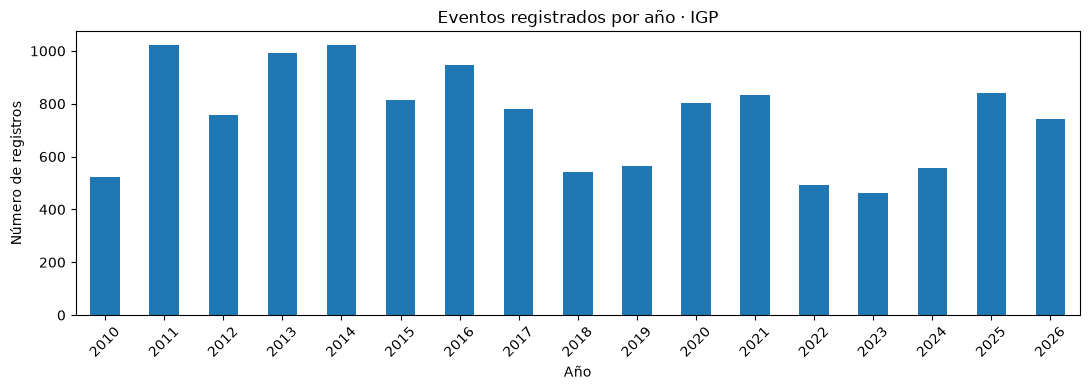

In [75]:
# ============================================================
# BLOQUE 6: Distribución anual de eventos.
# ============================================================
conteo_anual = trabajo.groupby("anio", dropna=False).size().rename("eventos")
display(conteo_anual.tail(12).to_frame())

for anio in (2023, 2024, 2025, 2026):
    print(f"{anio}: {int((trabajo['anio'] == anio).sum())} registros")

# ============================================================
# BLOQUE 7: Gráfica exploratoria (no predicción sísmica).
# ============================================================
serie_reciente = conteo_anual.loc[conteo_anual.index.notna()]
serie_reciente = serie_reciente.loc[serie_reciente.index >= 2010]
ax = serie_reciente.plot(kind="bar", figsize=(11, 4), title="Eventos registrados por año · IGP")
ax.set_xlabel("Año")
ax.set_ylabel("Número de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Validar rangos y completar el diagnóstico

Se examinan los campos numéricos tal como figuran en la exportación, sin descartar valores potencialmente válidos por criterio automático. `2026` es un año parcial; no comparar su total directamente con años completos sin aclaración.


In [76]:
# ============================================================
# BLOQUE 8: Inspección numérica y coordenadas.
# ============================================================
columnas_numericas = [
    c for c in trabajo.columns
    if any(p in c for p in ("latitud", "longitud", "profundidad", "magnitud"))
]
for columna in columnas_numericas:
    trabajo[f"{columna}_num"] = pd.to_numeric(trabajo[columna], errors="coerce")

cols_validacion = [f"{c}_num" for c in columnas_numericas]
display(trabajo[cols_validacion].describe().T)

col_lat = next((c for c in columnas_numericas if "latitud" in c), None)
col_lon = next((c for c in columnas_numericas if "longitud" in c), None)
if col_lat is not None and col_lon is not None:
    lat = trabajo[f"{col_lat}_num"]
    lon = trabajo[f"{col_lon}_num"]
    fuera = lat.notna() & lon.notna() & (~lat.between(-90, 90) | ~lon.between(-180, 180))
    print("Coordenadas fuera del rango terrestre:", int(fuera.sum()))

print("Inspección completada. Aún NO se han eliminado, fusionado ni exportado eventos.")


,count,mean,std,min,25%,50%,75%,max
latitud_o_num,25799.0,-11.392811,4.471535,-20.3100,-15.39010,-11.7946,-7.9684,-1.07
longitud_o_num,25799.0,-75.693049,3.087296,-82.8937,-77.73215,-75.7289,-73.6066,-67.64
profundidad_km_num,25799.0,70.313268,65.225521,5.0000,29.00000,48.0000,105.0000,743.00
magnitud_m_num,25799.0,4.667603,0.478190,3.0000,4.50000,4.6000,4.9000,8.40


Coordenadas fuera del rango terrestre: 0
Inspección completada. Aún NO se han eliminado, fusionado ni exportado eventos.


## 7. Criterios para la siguiente etapa

1. Revisar conteos por año y anomalías encontradas; contrastar especialmente 2024 con el CSV anterior.
2. Confirmar formatos de **fecha UTC**, **hora UTC**, **profundidad km** y **magnitud** con las fuentes del IGP.
3. Diseñar la normalización de `occurred_at` a UTC, preservando los valores originales.
4. Investigar la ausencia de un identificador estable por evento antes de decidir deduplicación y `external_id`.
5. Documentar transformaciones y preparar pruebas unitarias; solo entonces diseñar un `dry-run` reproducible.

**Estado de Fase 3: EN DESARROLLO. No se ejecuta SQL ni se escribe en Supabase.**


In [77]:
# =====================================================
# BLOQUE 1: Crear copia para la normalización temporal.
# =====================================================

normalizado = trabajo.copy()

# =====================================================
# BLOQUE 2: Preparar fecha y hora originales.
# =====================================================

fecha = normalizado["fecha_utc"].astype("string").str.strip()
hora = normalizado["hora_utc"].astype("string").str.strip()

# =====================================================
# BLOQUE 3: Construir la marca temporal en UTC.
# ISO8601 admite segundos con fracciones.
# errors="coerce" permite detectar valores inválidos.
# =====================================================

normalizado["occurred_at"] = pd.to_datetime(
    fecha + " " + hora,
    format="ISO8601",
    errors="coerce",
    utc=True
)

# =====================================================
# BLOQUE 4: Evaluar el resultado de la conversión.
# =====================================================

total = len(normalizado)
validos = normalizado["occurred_at"].notna().sum()
invalidos = normalizado["occurred_at"].isna().sum()

print("Total de registros:", total)
print("Fechas y horas válidas:", validos)
print("Fechas y horas inválidas:", invalidos)

print("\nTipo de dato:")
print(normalizado["occurred_at"].dtype)

print("\nPrimera fecha y hora:")
print(normalizado["occurred_at"].min())

print("\nÚltima fecha y hora:")
print(normalizado["occurred_at"].max())

# =====================================================
# BLOQUE 5: Inspeccionar registros problemáticos.
# No se elimina ni modifica ninguna fila.
# =====================================================

if invalidos > 0:
    display(
        normalizado.loc[
            normalizado["occurred_at"].isna(),
            ["fecha_utc", "hora_utc"]
        ].head(20)
    )
else:
    print("\nTodas las fechas y horas fueron interpretadas.")


Total de registros: 25799
Fechas y horas válidas: 25799
Fechas y horas inválidas: 0

Tipo de dato:
datetime64[us, UTC]

Primera fecha y hora:
1960-01-13 15:40:34+00:00

Última fecha y hora:
2026-10-21 03:12:48+00:00

Todas las fechas y horas fueron interpretadas.


In [78]:
# =====================================================
# BLOQUE 1: Copia de seguridad lógica para validaciones.
# Conservamos el DataFrame original sin modificaciones.
# =====================================================

calidad = normalizado.copy()

# =====================================================
# BLOQUE 2: Convertir las variables sísmicas a números.
# Los valores incorrectos se convierten en NaN.
# =====================================================

columnas = {
    "latitud_o": "latitude",
    "longitud_o": "longitude",
    "profundidad_km": "depth_km",
    "magnitud_m": "magnitude"
}

for origen, destino in columnas.items():
    calidad[destino] = pd.to_numeric(
        calidad[origen],
        errors="coerce"
    )

# =====================================================
# BLOQUE 3: Comprobar valores nulos y coordenadas.
# =====================================================

campos = [
    "occurred_at",
    "latitude",
    "longitude",
    "depth_km",
    "magnitude"
]

nulos = calidad[campos].isna().sum()

latitud_invalida = (
    calidad["latitude"].notna()
    & ~calidad["latitude"].between(-90, 90)
)

longitud_invalida = (
    calidad["longitude"].notna()
    & ~calidad["longitude"].between(-180, 180)
)

# =====================================================
# BLOQUE 4: Identificar profundidades que requieren revisión.
# No eliminamos valores negativos automáticamente.
# =====================================================

profundidad_negativa = (
    calidad["depth_km"] < 0
).sum()

# =====================================================
# BLOQUE 5: Identificar coincidencias exactas.
# Esto no demuestra que los eventos sean el mismo sismo.
# =====================================================

claves_comparacion = [
    "occurred_at",
    "latitude",
    "longitude",
    "depth_km",
    "magnitude"
]

duplicados = calidad.duplicated(
    subset=claves_comparacion,
    keep=False
)

duplicados_adicionales = calidad.duplicated(
    subset=claves_comparacion,
    keep="first"
).sum()

# =====================================================
# BLOQUE 6: Mostrar informe de validación.
# =====================================================

print("=== VALIDACIÓN DE CALIDAD IGP ===")
print("Registros analizados:", len(calidad))
print("\nValores nulos por campo:")
print(nulos.to_string())

print("\nCoordenadas inválidas:")
print("Latitud:", latitud_invalida.sum())
print("Longitud:", longitud_invalida.sum())

print("\nProfundidades negativas:", profundidad_negativa)

print("\nFilas en grupos de coincidencia:", duplicados.sum())
print("Filas adicionales coincidentes:", duplicados_adicionales)

print("\nRango de magnitudes:")
print(calidad["magnitude"].min(), "a", calidad["magnitude"].max())

print("\nRango de profundidades (km):")
print(calidad["depth_km"].min(), "a", calidad["depth_km"].max())

# =====================================================
# BLOQUE 7: Mostrar coincidencias para revisión.
# No se elimina ni modifica ningún registro.
# =====================================================

if duplicados.any():
    display(
        calidad.loc[
            duplicados,
            claves_comparacion
        ].sort_values("occurred_at").head(20)
    )
else:
    print("\nNo se encontraron coincidencias exactas.")


=== VALIDACIÓN DE CALIDAD IGP ===
Registros analizados: 25799

Valores nulos por campo:
occurred_at    0
latitude       0
longitude      0
depth_km       0
magnitude      0

Coordenadas inválidas:
Latitud: 0
Longitud: 0

Profundidades negativas: 0

Filas en grupos de coincidencia: 0
Filas adicionales coincidentes: 0

Rango de magnitudes:
3.0 a 8.4

Rango de profundidades (km):
5 a 743

No se encontraron coincidencias exactas.


In [79]:
# =====================================================
# BLOQUE 1: Configurar el periodo consultado al IGP.
# =====================================================

inicio = pd.Timestamp("1960-01-01", tz="UTC")
fin_exclusivo = pd.Timestamp("2026-10-22", tz="UTC")

# =====================================================
# BLOQUE 2: Definir los límites geográficos de consulta.
# Estos límites representan un rectángulo de búsqueda,
# no las fronteras políticas del Perú.
# =====================================================

lat_sur = -20.345
lat_norte = 0.718
lon_oeste = -88.096
lon_este = -66.590

# =====================================================
# BLOQUE 3: Validar el periodo temporal.
# =====================================================

fuera_periodo = (
    (calidad["occurred_at"] < inicio)
    | (calidad["occurred_at"] >= fin_exclusivo)
    | calidad["occurred_at"].isna()
)

# =====================================================
# BLOQUE 4: Validar la cobertura geográfica.
# =====================================================

fuera_zona = ~(
    calidad["latitude"].between(lat_sur, lat_norte)
    & calidad["longitude"].between(lon_oeste, lon_este)
)

# =====================================================
# BLOQUE 5: Mostrar resultados de la auditoría.
# =====================================================

print("=== VALIDACIÓN GEOGRÁFICA Y TEMPORAL ===")

print("Total de registros:", len(calidad))
print("Registros fuera del periodo:", fuera_periodo.sum())
print("Registros fuera de la zona:", fuera_zona.sum())

print(
    "Registros que requieren revisión:",
    (fuera_periodo | fuera_zona).sum()
)

# =====================================================
# BLOQUE 6: Identificar registros problemáticos.
# No se elimina ni modifica ningún evento.
# =====================================================

requieren_revision = fuera_periodo | fuera_zona

if requieren_revision.any():
    display(
        calidad.loc[
            requieren_revision,
            [
                "occurred_at",
                "latitude",
                "longitude",
                "depth_km",
                "magnitude"
            ]
        ].head(20)
    )
else:
    print(
        "\nTodos los registros están dentro de "
        "la ventana temporal y geográfica."
    )


=== VALIDACIÓN GEOGRÁFICA Y TEMPORAL ===
Total de registros: 25799
Registros fuera del periodo: 0
Registros fuera de la zona: 0
Registros que requieren revisión: 0

Todos los registros están dentro de la ventana temporal y geográfica.


In [80]:
# =====================================================
# BLOQUE 1: Seleccionar campos sísmicos validados.
# Mantener el DataFrame original sin modificar.
# =====================================================

eventos_normalizados = calidad[
    [
        "occurred_at",
        "latitude",
        "longitude",
        "depth_km",
        "magnitude"
    ]
].copy()

# =====================================================
# BLOQUE 2: Incorporar metadatos de procedencia.
# La URL corresponde al repositorio general del IGP,
# no a una ficha individual de cada evento.
# =====================================================

eventos_normalizados["source_url"] = (
    "https://ultimosismo.igp.gob.pe/repositorio/datos-sismicos"
)

# =====================================================
# BLOQUE 3: Preparar campos opcionales.
# No inventar identificadores, ubicaciones ni escalas.
# =====================================================

eventos_normalizados["external_id"] = None
eventos_normalizados["magnitude_type"] = None
eventos_normalizados["place"] = None

# =====================================================
# BLOQUE 4: Establecer estado inicial de revisión.
# Ningún registro ha sido aprobado para persistencia.
# =====================================================

eventos_normalizados["review_status"] = "pending"

# =====================================================
# BLOQUE 5: Organizar columnas según el modelo actual.
# Los UUID y fechas de recepción se asignarán
# posteriormente mediante la capa de persistencia.
# =====================================================

columnas_finales = [
    "external_id",
    "occurred_at",
    "latitude",
    "longitude",
    "magnitude",
    "magnitude_type",
    "depth_km",
    "place",
    "source_url",
    "review_status"
]

eventos_normalizados = eventos_normalizados[
    columnas_finales
]

# =====================================================
# BLOQUE 6: Validar dimensiones y estructura.
# =====================================================

print("=== DATASET NORMALIZADO IGP ===")
print("Filas:", len(eventos_normalizados))
print("Columnas:", len(eventos_normalizados.columns))

print("\nNombres de columnas:")
print(eventos_normalizados.columns.tolist())

print("\nTipos de datos:")
print(eventos_normalizados.dtypes)

print("\nPrimeros cinco registros:")
display(eventos_normalizados.head())

# =====================================================
# BLOQUE 7: Verificar que no se perdieron registros.
# =====================================================

assert len(eventos_normalizados) == len(calidad), (
    "Se detectó una pérdida de registros."
)

assert eventos_normalizados["occurred_at"].notna().all(), (
    "Existen fechas sin normalizar."
)

print("\nValidación de integridad: OK")
print("No se modificó Supabase.")


=== DATASET NORMALIZADO IGP ===
Filas: 25799
Columnas: 10

Nombres de columnas:
['external_id', 'occurred_at', 'latitude', 'longitude', 'magnitude', 'magnitude_type', 'depth_km', 'place', 'source_url', 'review_status']

Tipos de datos:
external_id                    object
occurred_at       datetime64[us, UTC]
latitude                      float64
longitude                     float64
magnitude                     float64
magnitude_type                 object
depth_km                        int64
place                          object
source_url                        str
review_status                     str
dtype: object

Primeros cinco registros:


,external_id,occurred_at,latitude,longitude,magnitude,magnitude_type,depth_km,place,source_url,review_status
0,None,1960-01-13 15:40:34+00:00,-16.145,-72.144,7.5,None,60,None,https://ultimosismo.igp.gob.pe/repositorio/dat...,pending
1,None,1960-01-15 09:30:24+00:00,-15.000,-75.000,7.0,None,70,None,https://ultimosismo.igp.gob.pe/repositorio/dat...,pending
2,None,1960-01-17 02:57:58+00:00,-14.500,-74.500,6.4,None,150,None,https://ultimosismo.igp.gob.pe/repositorio/dat...,pending
3,None,1960-01-23 03:37:32+00:00,-12.500,-68.500,5.8,None,300,None,https://ultimosismo.igp.gob.pe/repositorio/dat...,pending
4,None,1960-01-30 05:07:24+00:00,-5.500,-77.500,5.7,None,100,None,https://ultimosismo.igp.gob.pe/repositorio/dat...,pending



Validación de integridad: OK
No se modificó Supabase.


In [81]:
# =====================================================
# BLOQUE 1: Importar bibliotecas para generar huellas.
# =====================================================

import hashlib
import json
from decimal import Decimal

# =====================================================
# BLOQUE 2: Normalizar la representación numérica.
# Evita diferencias como 7, 7.0 y 7.00.
# =====================================================

def numero_canonico(valor):
    numero = Decimal(str(valor))

    if not numero.is_finite():
        raise ValueError("Valor numérico no finito")

    if numero == 0:
        return "0"

    return format(numero.normalize(), "f")

# =====================================================
# BLOQUE 3: Crear una huella técnica reproducible.
# Incluimos la fuente para separar proveedores.
# =====================================================

def generar_huella(fecha, lat, lon, profundidad, magnitud):
    instante = pd.Timestamp(fecha).tz_convert("UTC")

    datos = {
        "fuente": "IGP",
        "occurred_at": instante.strftime(
            "%Y-%m-%dT%H:%M:%S.%fZ"
        ),
        "latitude": numero_canonico(lat),
        "longitude": numero_canonico(lon),
        "depth_km": numero_canonico(profundidad),
        "magnitude": numero_canonico(magnitud),
    }

    contenido = json.dumps(
        datos,
        sort_keys=True,
        separators=(",", ":")
    )

    return hashlib.sha256(
        contenido.encode("utf-8")
    ).hexdigest()

# =====================================================
# BLOQUE 4: Generar huellas sin alterar el original.
# =====================================================

identidad = eventos_normalizados.copy()

campos_identidad = [
    "occurred_at",
    "latitude",
    "longitude",
    "depth_km",
    "magnitude"
]

identidad["record_fingerprint"] = [
    generar_huella(*fila)
    for fila in identidad[campos_identidad].itertuples(
        index=False,
        name=None
    )
]

# =====================================================
# BLOQUE 5: Buscar huellas repetidas.
# =====================================================

total = len(identidad)
huellas_unicas = identidad["record_fingerprint"].nunique()
duplicados = identidad["record_fingerprint"].duplicated().sum()

print("=== AUDITORÍA DE IDENTIDAD IGP ===")
print("Registros analizados:", total)
print("Huellas únicas:", huellas_unicas)
print("Huellas duplicadas adicionales:", duplicados)

# =====================================================
# BLOQUE 6: Mostrar una muestra verificable.
# =====================================================

display(
    identidad[
        ["occurred_at", "magnitude", "record_fingerprint"]
    ].head()
)

# =====================================================
# BLOQUE 7: Comprobar integridad.
# =====================================================

assert len(identidad) == len(eventos_normalizados)

assert identidad["record_fingerprint"].notna().all()

print("\nIntegridad de huellas: OK")
print("No se modificó Supabase.")


=== AUDITORÍA DE IDENTIDAD IGP ===
Registros analizados: 25799
Huellas únicas: 25799
Huellas duplicadas adicionales: 0


,occurred_at,magnitude,record_fingerprint
0,1960-01-13 15:40:34+00:00,7.5,95d65b8bdff5e0919b1c73e973f9e2953f2e20f64d921a...
1,1960-01-15 09:30:24+00:00,7.0,d93061621110505a3c5e4e5d732d8d233f9c359a583e85...
2,1960-01-17 02:57:58+00:00,6.4,26fea3d25b5b73b45e3a4ea39d01d4a462a1eb1216f042...
3,1960-01-23 03:37:32+00:00,5.8,f82533b8a027eba545ffd014d9ef42ca7afd4eaf14f849...
4,1960-01-30 05:07:24+00:00,5.7,ebd1121ef18768bd6647bffc0d8b7f17a46c4dc6c0fe9b...



Integridad de huellas: OK
No se modificó Supabase.


In [82]:
# =====================================================
# BLOQUE 1: Importar funciones matemáticas.
# =====================================================

from math import radians, sin, cos, asin, sqrt

# =====================================================
# BLOQUE 2: Distancia geográfica aproximada.
# Fórmula de Haversine, resultado en kilómetros.
# =====================================================

def distancia_km(lat1, lon1, lat2, lon2):
    radio_tierra = 6371.0088

    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)

    a = (
        sin(dlat / 2) ** 2
        + cos(radians(lat1))
        * cos(radians(lat2))
        * sin(dlon / 2) ** 2
    )

    return 2 * radio_tierra * asin(min(1, sqrt(a)))

# =====================================================
# BLOQUE 3: Ordenar eventos por instante.
# Se conserva el índice original para rastrear filas.
# =====================================================

auditoria = (
    identidad.reset_index()
    .rename(columns={"index": "fila_original"})
    .sort_values("occurred_at")
    .reset_index(drop=True)
)

# =====================================================
# BLOQUE 4: Definir umbrales exploratorios.
# =====================================================

ventana_tiempo = pd.Timedelta(seconds=120)
max_distancia = 20
max_diferencia_magnitud = 0.3
max_diferencia_profundidad = 30

# =====================================================
# BLOQUE 5: Comparar pares dentro de la ventana temporal.
# El orden temporal evita comparar todos contra todos.
# =====================================================

candidatos = []

for i in range(len(auditoria)):
    evento_a = auditoria.iloc[i]

    j = i + 1

    while j < len(auditoria):
        evento_b = auditoria.iloc[j]

        diferencia_tiempo = (
            evento_b["occurred_at"]
            - evento_a["occurred_at"]
        ).total_seconds()

        if diferencia_tiempo > 120:
            break

        distancia = distancia_km(
            evento_a["latitude"],
            evento_a["longitude"],
            evento_b["latitude"],
            evento_b["longitude"]
        )

        diferencia_magnitud = abs(
            evento_a["magnitude"] - evento_b["magnitude"]
        )

        diferencia_profundidad = abs(
            evento_a["depth_km"] - evento_b["depth_km"]
        )

        if (
            distancia <= max_distancia
            and diferencia_magnitud <= max_diferencia_magnitud
            and diferencia_profundidad <= max_diferencia_profundidad
        ):
            candidatos.append({
                "fila_a": int(evento_a["fila_original"]),
                "fila_b": int(evento_b["fila_original"]),
                "tiempo_seg": diferencia_tiempo,
                "distancia_km": round(distancia, 2),
                "diferencia_magnitud": round(
                    diferencia_magnitud, 3
                ),
                "diferencia_profundidad": float(
                    diferencia_profundidad
                )
            })

        j += 1

# =====================================================
# BLOQUE 6: Mostrar informe sin eliminar registros.
# =====================================================

candidatos_df = pd.DataFrame(candidatos)

print("=== AUDITORÍA DE POSIBLES DUPLICADOS ===")
print("Registros analizados:", len(auditoria))
print("Pares candidatos:", len(candidatos_df))

if not candidatos_df.empty:
    display(candidatos_df.head(20))
else:
    print("No se encontraron pares con estos umbrales.")

print("\nNo se eliminaron registros.")
print("No se modificó Supabase.")


=== AUDITORÍA DE POSIBLES DUPLICADOS ===
Registros analizados: 25799
Pares candidatos: 21


,fila_a,fila_b,tiempo_seg,distancia_km,diferencia_magnitud,diferencia_profundidad
0,4639,4640,61.0,8.67,0.0,0.0
1,4643,4644,59.0,5.54,0.0,0.0
2,7220,7221,120.0,0.00,0.0,0.0
3,7253,7254,61.0,15.86,0.1,14.0
4,9307,9308,93.0,18.49,0.2,15.0
5,9310,9311,38.0,9.07,0.0,0.0
6,9330,9331,83.0,5.58,0.3,0.0
7,9331,9332,8.0,16.55,0.1,0.0
8,11062,11063,53.0,12.00,0.1,17.0
9,12243,12244,87.0,2.40,0.0,3.0



No se eliminaron registros.
No se modificó Supabase.


In [83]:
# =====================================================
# BLOQUE 1: Preparar columnas de revisión.
# No modificamos los registros originales.
# =====================================================

columnas_evento = [
    "occurred_at",
    "latitude",
    "longitude",
    "depth_km",
    "magnitude"
]

# =====================================================
# BLOQUE 2: Recuperar los eventos de cada pareja.
# Los índices corresponden a las filas originales.
# =====================================================

if candidatos_df.empty:
    print("No hay pares candidatos para inspeccionar.")

else:
    assert identidad.index.is_unique, (
        "Los índices originales deben ser únicos."
    )

    eventos_a = (
        identidad.loc[
            candidatos_df["fila_a"].to_numpy(),
            columnas_evento
        ]
        .reset_index(drop=True)
        .add_prefix("a_")
    )

    eventos_b = (
        identidad.loc[
            candidatos_df["fila_b"].to_numpy(),
            columnas_evento
        ]
        .reset_index(drop=True)
        .add_prefix("b_")
    )

    # =================================================
    # BLOQUE 3: Unir datos de ambos eventos.
    # =================================================

    pares_detallados = pd.concat(
        [
            candidatos_df.reset_index(drop=True),
            eventos_a,
            eventos_b
        ],
        axis=1
    )

    # =================================================
    # BLOQUE 4: Ordenar por proximidad temporal.
    # Solo ayuda a priorizar la revisión manual.
    # =================================================

    pares_detallados = (
        pares_detallados.sort_values(
            ["tiempo_seg", "distancia_km"]
        )
        .reset_index(drop=True)
    )

    # =================================================
    # BLOQUE 5: Mostrar la auditoría completa.
    # =================================================

    print("=== REVISIÓN DETALLADA DE PARES ===")
    print("Pares candidatos:", len(pares_detallados))

    print(
        "Filas diferentes involucradas:",
        len(
            set(pares_detallados["fila_a"])
            | set(pares_detallados["fila_b"])
        )
    )

    with pd.option_context(
        "display.max_columns", None,
        "display.max_rows", 30
    ):
        display(pares_detallados)

    # =================================================
    # BLOQUE 6: Confirmar que no se alteraron datos.
    # =================================================

    assert len(identidad) == 25799

    print("\nRegistros originales conservados.")
    print("No se modificó Supabase.")


=== REVISIÓN DETALLADA DE PARES ===
Pares candidatos: 21
Filas diferentes involucradas: 41


,fila_a,fila_b,tiempo_seg,distancia_km,diferencia_magnitud,diferencia_profundidad,a_occurred_at,a_latitude,a_longitude,a_depth_km,a_magnitude,b_occurred_at,b_latitude,b_longitude,b_depth_km,b_magnitude
0,13420,13421,1.0,7.20,0.0,0.0,2010-09-22 21:02:51+00:00,-15.0526,-73.6256,88,4.5,2010-09-22 21:02:52+00:00,-14.9948,-73.6559,88,4.5
1,14009,14010,1.0,7.83,0.0,3.0,2011-06-18 01:16:07+00:00,-15.3902,-74.3300,46,4.7,2011-06-18 01:16:08+00:00,-15.4242,-74.3940,49,4.7
2,16108,16109,1.0,9.07,0.0,2.0,2013-10-11 05:09:10+00:00,-3.4432,-79.8531,62,4.5,2013-10-11 05:09:11+00:00,-3.4916,-79.9189,60,4.5
3,9331,9332,8.0,16.55,0.1,0.0,2001-06-24 05:05:09+00:00,-16.7470,-73.9820,33,4.5,2001-06-24 05:05:17+00:00,-16.8710,-73.8960,33,4.6
4,9310,9311,38.0,9.07,0.0,0.0,2001-06-24 02:29:47+00:00,-17.0640,-73.5490,33,5.0,2001-06-24 02:30:25+00:00,-17.0100,-73.6130,33,5.0
5,11062,11063,53.0,12.00,0.1,17.0,2005-03-15 20:44:58+00:00,-4.6010,-77.9151,29,4.6,2005-03-15 20:45:51+00:00,-4.5089,-77.8586,46,4.5
6,13385,13386,56.0,19.52,0.1,3.0,2010-09-04 02:09:07+00:00,-14.6215,-76.3536,20,4.8,2010-09-04 02:10:03+00:00,-14.7817,-76.4279,23,4.9
7,4643,4644,59.0,5.54,0.0,0.0,1991-04-08 22:35:45+00:00,-5.9800,-77.2000,27,4.8,1991-04-08 22:36:44+00:00,-6.0100,-77.1600,27,4.8
8,12346,12347,60.0,13.39,0.3,27.0,2007-08-21 21:31:21+00:00,-13.5397,-76.9315,16,5.6,2007-08-21 21:32:21+00:00,-13.5803,-77.0481,43,5.3
9,4639,4640,61.0,8.67,0.0,0.0,1991-04-08 08:50:08+00:00,-5.8600,-77.0600,28,4.7,1991-04-08 08:51:09+00:00,-5.9200,-77.1100,28,4.7



Registros originales conservados.
No se modificó Supabase.
